# **Capitolo 4. Analisi del Dataset delle Recensioni Clienti**

Dopo aver garantito l’integrità strutturale del dataset, l’attenzione si sposta sul **contenuto delle recensioni**. L’obiettivo è duplice: caratterizzare il corpus dal punto di vista strutturale e lessicale e individuare eventuali pattern comportamentali utili alla comprensione complessiva del fenomeno. 

> Questo secondo notebook riguardante le procedure descritte nel quarto capitolo, si occupa dell'analisi esplorativa del corpus testuale (*l'intero paragrafo 4.2 con annessi sottoparagrafi*).

## **4.2. Analisi esplorativa del corpus testuale**

Configuriamo l'ambiente di lavoro e importiamo i dati ottenuti al termine del notebook precedente `1_cleaning__recensioni.ipynb`.

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import math
from langdetect import detect, DetectorFactory
import emoji
from collections import Counter
from wordcloud import WordCloud
from tqdm import tqdm
from IPython.display import display, HTML
import nltk
from nltk.corpus import stopwords
from lingua import Language, LanguageDetectorBuilder
from deep_translator import GoogleTranslator
import time

# Preparazione dell'ambiente
DetectorFactory.seed = 0 
tqdm.pandas()
sns.set_theme(style="whitegrid", palette="muted")

while not os.path.exists("Circular Second Hand") and os.getcwd() != os.path.dirname(os.getcwd()):
    os.chdir("..")

print(f"Jupyter è allineato. Cartella di lavoro attuale:\n{os.getcwd()}.\n")


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [3]:
df = pd.read_csv(r'Circular Second Hand\Analisi\Analisi - Recensioni\Risultati Analisi - Recensioni\1_cleaning__recensioni.csv')
print(f"Dimensioni dataset originale: {df.shape}.\n")

Dimensioni dataset originale: (97545, 18).



Costruiamo la variabile testuale principale su cui verrà effettuata l’analisi NLP. Ogni record del dataset contiene infatti due componenti distinte, Titolo Recensione e Testo Recensione, che vengono unite in un unico campo denominato **Testo Integrale**, al fine di preservare la totalità dell’informazione semantica disponibile. Prima della concatenazione, si procede alla normalizzazione dei valori mancanti. 

In [4]:
# Gestione valori mancanti e creazione Testo Integrale
# Sostituiamo i trattini e i valori nulli con stringhe vuote
# per permettere la concatenazione vettoriale senza generare errori o NaN indesiderati.
df['Titolo Recensione'] = df['Titolo Recensione'].replace('-', '').fillna('')
df['Testo Recensione'] = df['Testo Recensione'].replace('-', '').fillna('')
# Concatenazione: uniamo Titolo e Testo in una nuova variabile
df['Testo Integrale'] = df['Titolo Recensione'] + " " + df['Testo Recensione']
df['Testo Integrale'] = df['Testo Integrale'].str.strip()

# Visualizzazione anteprima dei risultati
display(HTML("<h3>Esempi di concatenazione (Titolo + Testo)</h3>"))
display(df[['Titolo Recensione', 'Testo Recensione', 'Testo Integrale']].head(3))

# Identificazione e conteggio dei valori mancanti
# Per identificare i record effettivamente vuoti, riportiamo temporaneamente le stringhe vuote a NaN
df['Testo Integrale'] = df['Testo Integrale'].replace('', np.nan)

titolo_vuoto = (df['Titolo Recensione'] == '').sum()
testo_vuoto = (df['Testo Recensione'] == '').sum()
entrambi_vuoti = df['Testo Integrale'].isna().sum()
totale = len(df)

# Funzione per arrotondare rigorosamente per difetto alla seconda cifra decimale
def calcola_perc_difetto(numeratore, denominatore):
    valore = (numeratore / denominatore) * 100
    return math.floor(valore * 100) / 100

# Tabella riassuntiva
df_missing = pd.DataFrame({
    'Componente': ['Solo Titolo Mancante', 'Solo Testo Mancante', 'Testo Integrale Mancante'],
    'Conteggio': [titolo_vuoto, testo_vuoto, entrambi_vuoti],
    'Percentuale': [f"{calcola_perc_difetto(titolo_vuoto, totale):.2f}%", 
                    f"{calcola_perc_difetto(testo_vuoto, totale):.2f}%", 
                    f"{calcola_perc_difetto(entrambi_vuoti, totale):.2f}%"]})

display(HTML("<h3>Analisi Valori Mancanti Testuali</h3>"))
display(df_missing)

# Filtraggio Dataset per EDA
# Creiamo il dataframe df_eda rimuovendo i record dove il Testo Integrale è nullo.
# Questi record non apporterebbero valore alla fase di analisi linguistica e NLP.
df_eda = df.dropna(subset=['Testo Integrale']).copy()

display(HTML(f"Recensioni completamente vuote rimosse: <b>{entrambi_vuoti}</b>."))
display(HTML(f"Dimensioni dataset attuale (fase di esplorazione): <b>{df_eda.shape}</b>."))

,Titolo Recensione,Testo Recensione,Testo Integrale
0,Comodissimo,"Tanto comodo che ""rapisce""!\nSemplicissimo anc...","Comodissimo Tanto comodo che ""rapisce""!\nSempl..."
1,ok,ok,ok ok
2,praticità,comodo e pratico si inserisce bene in ogni tip...,praticità comodo e pratico si inserisce bene i...


,Componente,Conteggio,Percentuale
0,Solo Titolo Mancante,6457,6.61%
1,Solo Testo Mancante,6,0.00%
2,Testo Integrale Mancante,5,0.00%


### **4.2.1 Rilevamento automatico della lingua e traduzione**

In un dataset di recensioni, la varietà linguistica rappresenta un valore aggiunto ma anche una sfida tecnica: i modelli di Natural Language Processing, infatti, raggiungono la massima precisione quando operano su un **corpus linguistico uniforme**. L'obiettivo di questo capitolo è identificare la lingua di ogni recensione per poter, in seguito, ricondurre tutto il patrimonio informativo verso l'italiano.

Per rilevare la lingua, si implementa una procedura divisa in tre livelli di controllo, basata sul framework `lingua-language-detector`:

1.  Filtraggio dei "Micro-testi": prima ancora di interrogare il rilevatore, isoliamo le recensioni composte da 2 o meno parole significative, casi etichettati come `micro_text` e trattati come lingua italiana.

2.  Soglie di Confidenza Adattive: invece di accettare passivamente il verdetto del software, abbiamo introdotto un sistema di "soglie dinamiche", dove, man mano che il testo diventa più lungo e ricco di informazioni, permettiamo al sistema di essere più flessibile. 

3.  Gestione dell'Incertezza: tutti i casi in cui l'algoritmo non raggiunge la soglia di sicurezza desiderata (`uncertain`) o non riesce a classificare il testo (`unknown`) vengono automaticamente ricondotti alla lingua italiana.

Rilevamento della lingua: 100%|██████████| 97540/97540 [00:36<00:00, 2707.66it/s]


,Lingua finale,Conteggio,Percentuale (%)
0,it,97373,99.83
1,en,150,0.15
2,es,12,0.01
3,pt,2,0.00
4,de,2,0.00
5,fr,1,0.00


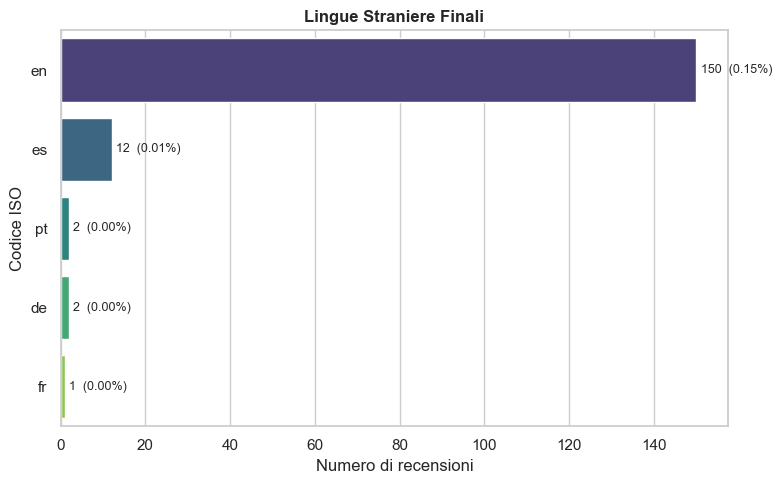

,Voto Generale Recensione,Testo Integrale,Lingua_raw
65277,5,funzionale funzionale,micro_text
51227,5,Ottimo Ottimo,micro_text
83334,4,Perfette Perfette,micro_text
60717,5,ottimo ottimo,micro_text
58752,4,Soddisfatto Soddisfatto,micro_text


,Voto Generale Recensione,Testo Integrale,Lingua_raw
57538,5,Pratico Bello e semplice nella sua forma,uncertain
80233,5,Utile Bello e utile,uncertain
49720,5,Perfette Perfette con il mio besta,uncertain
27854,5,Comode Comode e resistenti,uncertain
21295,4,Ottimo design Ottimo design,uncertain


,Voto Generale Recensione,Testo Integrale
44642,5,"Difficult to mount, but well worth the effort Pros:This product offers a fantastic aesthetic effect when lights on, and also smart design that allows turn on-off the 2 rings using the remote control. Light intensity can be regulated too. \nCons: it's not so light, you will definitely need help from (at least) 1 person to mount this on the ceiling. Also once the LED rings are broken, no possibility to replace the bulb as usual, need to buy an entirely new lamp"
12068,5,Great inexpensive chair for high Great inexpensive chair for high table
82198,5,"Perfect for putting order. It’s the perfect size, easy to assemble and clean."


,Voto Generale Recensione,Testo Integrale
90047,5,Bellísima e il montaggio e facilísimo una super lampada
77060,5,Cómodo per la mia bambina Cómodo per la mia bambina di 2 anni
8830,5,"Es un muy buen producto, Es un muy buen producto, la medida es óptima"


,Voto Generale Recensione,Testo Integrale
49540,4,"Um pouco fino Prático porém fino, atende para pequeninhos, porém o uso o para adulto deixa a desejar"
18759,5,Perfetto!!! Deixou o quarto do meu filho lindo!!!


In [ ]:
# RILEVAMENTO AUTOMATICO DELLA LINGUA
# Configurazione detector
lingue_candidate = [Language.ITALIAN, Language.ENGLISH, Language.SPANISH, Language.FRENCH, Language.PORTUGUESE, Language.ROMANIAN, Language.GERMAN,Language.DUTCH,]
detector = (LanguageDetectorBuilder.from_languages(*lingue_candidate).with_minimum_relative_distance(0.1).build())

# Funzione di rilevamento con confidence e soglia adattiva
# Rileva la lingua con soglia adattiva alla lunghezza del testo.
# Restituisce: codice ISO 639-1 ('it', 'en', 'es', ...); 'micro_text' per testo con <= 2 parole riconoscibili; 
# 'uncertain' con confidence sotto soglia adattiva; unknown' per nessun risultato dal detector.

def rileva_lingua(testo: str) -> str:
    testo_str = str(testo).strip()
    parole = re.findall(r'\b[a-zàèéìíòóùú]{2,}\b', testo_str.lower())

    if len(parole) <= 2:
        return 'micro_text'

    risultati = detector.compute_language_confidence_values(testo_str)
    if not risultati:
        return 'unknown'

    top    = risultati[0]
    lingua = top.language.iso_code_639_1.name.lower()
    score  = top.value

    # Soglia adattiva
    if   len(parole) <= 6:  soglia = 0.80
    elif len(parole) <= 15: soglia = 0.65
    else:                   soglia = 0.50

    return lingua if score >= soglia else 'uncertain'

# Avvio rilevamento con barra progressiva
display(HTML("<h3>Rilevamento Lingua</h3>"))
tqdm.pandas(desc="Rilevamento della lingua", colour='green')
df_eda['Lingua_raw'] = df_eda['Testo Integrale'].progress_apply(rileva_lingua)

# In caso di testi 'ambigui', essi vengono inseriti come testi in lingua italiana
SOSTITUZIONI = {'micro_text': 'it', 'uncertain': 'it', 'unknown': 'it'}
df_eda['Lingua'] = df_eda['Lingua_raw'].replace(SOSTITUZIONI)

display(HTML("<p><b>Sostituzione applicata:</b> " "<code>micro_text</code>, <code>uncertain</code>, <code>unknown</code> → <code>it</code></p>"))

# Tabella riassuntiva
tot = len(df_eda)
dist_final = df_eda['Lingua'].value_counts()

df_final = pd.DataFrame({'Lingua finale':   dist_final.index,
                        'Conteggio':       dist_final.values,
                        'Percentuale (%)': (dist_final.values / tot * 100).round(2)})

display(HTML("<h4>Distribuzione Finale (dopo la sostituzione)</h4>"))
display(df_final)

# Visualizzazione: lingue straniere finali
plt.figure(figsize=(8, 5))
straniere = df_final[df_final['Lingua finale'] != 'it'].head(10)

if not straniere.empty:
    ax = sns.barplot(data=straniere, x='Conteggio', y='Lingua finale', hue='Lingua finale', palette='viridis', legend=False)
    plt.title('Lingue Straniere Finali', fontsize=12, fontweight='bold')
    plt.xlabel('Numero di recensioni')
    plt.ylabel('Codice ISO')
    # Etichette con valori e percentuali
    for i, v in enumerate(straniere['Conteggio']):
        plt.text(v + 1, i, f'{v}  ({v/tot*100:.2f}%)', va='center', fontsize=9)

else:
    plt.text(0.5, 0.5, 'Nessuna lingua straniera rilevata',
             ha='center', va='center', fontsize=12)
    plt.axis('off')

plt.tight_layout()
plt.show()

# Ispezione campioni
display(HTML("<h3>Ispezione Campioni per Categoria</h3>"))

for cat in ('micro_text', 'uncertain', 'unknown'):
    subset = df_eda[df_eda['Lingua_raw'] == cat]
    if len(subset) == 0:
        continue
    display(HTML(
        f"<h4>Categoria raw: <code>{cat}</code> "
        f"→ {len(subset):,} recensioni ({len(subset)/tot*100:.2f}%) "
        f"→ mappate a <code>it</code></h4>"
    ))
    with pd.option_context('display.max_colwidth', None):
        display(
            subset[['Voto Generale Recensione', 'Testo Integrale', 'Lingua_raw']]
            .sample(min(5, len(subset)), random_state=42)
        )

lingue_straniere_reali = [l for l in df_eda['Lingua'].unique() if l != 'it']
for lingua in lingue_straniere_reali[:3]:
    subset = df_eda[df_eda['Lingua'] == lingua]
    display(HTML(f"<h4>Lingua straniera: <code>{lingua.upper()}</code> → {len(subset):,} recensioni</h4>"))
    with pd.option_context('display.max_colwidth', None):
        display(subset[['Voto Generale Recensione', 'Testo Integrale']].sample(min(3, len(subset)), random_state=42))

Identificate le recensioni scritte in lingue estere, procediamo con la loro traduzione sistematica verso l'italiano.

In [ ]:
# TRADUZIONE AUTOMATICA
display(HTML("<h3>Traduzione Automatica in Italiano</h3>"))

# Identifichiamo le righe da tradurre
mask_straniere = df_eda['Lingua'] != 'it'
n_da_tradurre  = mask_straniere.sum()

display(HTML(f"<p>Recensioni da tradurre: <b>{n_da_tradurre:,}</b> ({n_da_tradurre/tot*100:.2f}% del totale)</p>"))

# Parametri traduttore
MAX_CHARS       = 4500   # Google Translate limite per chiamata (~5000 caratteri)
PAUSA_SECONDI   = 0.05   # Pausa tra richieste (evita rate-limit; aumenta se ci sono errori)
MAX_RETRY       = 3      # Tentativi in caso di errore di rete

# Funzione che traduce 'testo' da 'lingua_src' all'italiano via Google Translate.
# Gestisce testi lunghi (chunking), retry su errore, e fallback al testo originale.

def traduci_testo(testo: str, lingua_src: str) -> str:
    testo_str = str(testo).strip()
    if not testo_str:
        return testo_str

    # Chunking: spezza testi lunghi in frasi rispettando il limite di caratteri
    if len(testo_str) <= MAX_CHARS:
        chunks = [testo_str]
    else:
        # Dividiamo per punto/a capo cercando di non spezzare le frasi
        frasi      = re.split(r'(?<=[.!?])\s+|\n', testo_str)
        chunks     = []
        chunk_cur  = ""
        for frase in frasi:
            if len(chunk_cur) + len(frase) + 1 <= MAX_CHARS:
                chunk_cur += (" " if chunk_cur else "") + frase
            else:
                if chunk_cur:
                    chunks.append(chunk_cur)
                # Frase da sola troppo lunga? Tagliamo a forza
                chunk_cur = frase[:MAX_CHARS]
        if chunk_cur:
            chunks.append(chunk_cur)

    tradotti = []
    for chunk in chunks:
        for tentativo in range(1, MAX_RETRY + 1):
            try:
                translator = GoogleTranslator(source=lingua_src, target='it')
                tradotti.append(translator.translate(chunk))
                time.sleep(PAUSA_SECONDI)
                break
            except Exception as e:
                if tentativo == MAX_RETRY:
                    # Fallback: testo originale non tradotto
                    tradotti.append(chunk)
                else:
                    time.sleep(0.5 * tentativo)  # Back-off progressivo

    return " ".join(tradotti)

# Creiamo la colonna di destinazione copiando il testo originale
df_eda['Testo Tradotto'] = df_eda['Testo Integrale'].copy()

# Traduciamo solo le righe straniere, con barra progressiva
if n_da_tradurre > 0:
    indici_stranieri = df_eda[mask_straniere].index

    with tqdm(total=n_da_tradurre,
              desc="Traduzione in corso",
              colour='blue',
              unit='recensione') as pbar:

        for idx in indici_stranieri:
            lingua_src = df_eda.at[idx, 'Lingua']
            testo_orig = df_eda.at[idx, 'Testo Integrale']
            df_eda.at[idx, 'Testo Tradotto'] = traduci_testo(testo_orig, lingua_src)
            pbar.update(1)

    display(HTML("<p><b>Traduzione completata.</b></p>"))
else:
    display(HTML("<p>Nessuna recensione straniera da tradurre.</p>"))

# Ispezione post-traduzione
display(HTML("<h3>Ispezione: Originale vs Tradotto</h3>"))

if n_da_tradurre > 0:
    campione = df_eda[mask_straniere][['Lingua', 'Testo Integrale', 'Testo Tradotto']].sample(min(4, n_da_tradurre), random_state=42)
    with pd.option_context('display.max_colwidth', None):
        display(campione)

Traduzione in corso: 100%|██████████| 167/167 [04:51<00:00,  1.74s/recensione]


,Lingua,Testo Integrale,Testo Tradotto
56222,en,Nice set but needs to be dry by wipes after washing,Bel set ma deve essere asciugato con le salviette dopo il lavaggio
64885,en,Good quality! Just the price Good quality! Just the price is a bit too expensive!,Buona qualità! Solo il prezzo Buona qualità! Solo che il prezzo è un po' troppo caro!
41705,en,"Table ;) We didn't ""inspect"" the display before purchasing ....\n\nWhile it is a nice table, and a great value .... we thought we were purchasing a wood table .... but it is a plastic table top with metal legs.\n\nNot quite what we were expecting/wanting .... but it's what we now have :)","Tabella ;) Non abbiamo ""ispezionato"" il display prima dell'acquisto....\n\nAnche se è un bel tavolo e di grande valore... pensavamo di acquistare un tavolo in legno... ma è un tavolo in plastica con gambe in metallo.\n\nNon proprio quello che ci aspettavamo/volevamo... ma è quello che abbiamo ora :)"
31147,en,Best ever cheap table Maximum quality*functionality / price ratio,Il miglior tavolo economico di sempre. Massimo rapporto qualità*funzionalità/prezzo


Un aspetto da verificare è se il processo di traduzione automatica preserva le emoji eventualmente presenti nel testo originale. Google Translate, non interpretando le emoji come elementi linguistici, le mantiene intatte nel testo tradotto, come confermato dagli esempi seguenti.

In [ ]:
display(HTML("<h3>Verifica: Conservazione delle Emoji dopo la Traduzione</h3>"))

df_straniere_emoji = df_eda[(df_eda['Lingua'] != 'it') & (df_eda['Testo Integrale'].apply(lambda x: len(emoji.emoji_list(str(x))) > 0))].copy()

n_trovate = len(df_straniere_emoji)
display(HTML(f"<p>Recensioni straniere con almeno un'emoji: <b>{n_trovate:,}</b></p>"))

if n_trovate > 0:
    with pd.option_context('display.max_colwidth', None):
        display(df_straniere_emoji[['Lingua', 'Voto Generale Recensione', 'Testo Integrale', 'Testo Tradotto']].sample(min(5, n_trovate), random_state=42))
else:
    display(HTML("<p><i>Nessuna recensione straniera con emoji trovata.</i></p>"))

,Lingua,Voto Generale Recensione,Testo Integrale,Testo Tradotto
58740,en,3,"I miss the old version I wish we could have the option of these AND the solid chest of drawers rather than only these. They are fine in theory and work, but they aren’t very big and seem quite flimsy. Please bring back the old drawers 🙏🙏","Mi manca la vecchia versione. Vorrei che potessimo avere l'opzione di questi E la solida cassettiera piuttosto che solo questi. Vanno bene in teoria e nel lavoro, ma non sono molto grandi e sembrano piuttosto fragili. Per favore, riporta indietro i vecchi cassetti 🙏🙏"


### **4.2.2. Analisi della lunghezza testuale**

Si conduce un'**analisi esplorativa della lunghezza dei testi**, al fine di comprendere la struttura distributiva dei dati e le modalità espressive degli utenti. Tale fase non ha finalità predittive, ma esclusivamente descrittive e preparatorie, in quanto consente di identificare pattern quantitativi utili alla successiva fase di preprocessing NLP.

In una prima fase vengono calcolate le principali metriche descrittive relative alla lunghezza delle recensioni testuali. Si procede con una segmentazione a soglie fisse (rule-based) del numero di parole. Tale approccio è definito a priori, in quanto non derivato dai dati ma da criteri interpretativi predefiniti.

,count,mean,std,min,25%,50%,75%,max
Num_Caratteri,97540.0,90.97,91.88,3.0,36.0,65.0,112.0,1746.0
Num_Parole,97540.0,14.26,15.10,1.0,5.0,10.0,18.0,286.0


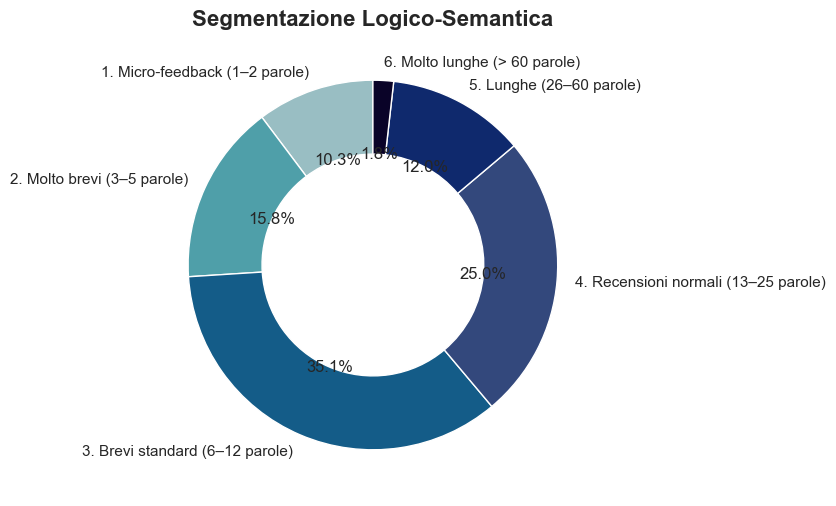

,Conteggio,Percentuale (%)
Fascia Lunghezza,,
1. Micro-feedback (1–2 parole),10004,10.26
2. Molto brevi (3–5 parole),15370,15.76
3. Brevi standard (6–12 parole),34252,35.12
4. Recensioni normali (13–25 parole),24417,25.03
5. Lunghe (26–60 parole),11743,12.04
6. Molto lunghe (> 60 parole),1754,1.80


In [ ]:
# Calcolo delle metriche di base
df_eda['Num_Caratteri'] = df_eda['Testo Tradotto'].apply(len)
df_eda['Num_Parole'] = df_eda['Testo Tradotto'].apply(lambda x: len(str(x).split()))

display(HTML("<h3>Statistiche Descrittive: Lunghezza del Testo</h3>"))
display(df_eda[['Num_Caratteri', 'Num_Parole']].describe().T.round(2))

# Suddivisione in fasce di lunghezza 
bins = [0, 2, 5, 12, 25, 60, float('inf')]
etichette = ["1. Micro-feedback (1–2 parole)",
            "2. Molto brevi (3–5 parole)",
            "3. Brevi standard (6–12 parole)",
            "4. Recensioni normali (13–25 parole)",
            "5. Lunghe (26–60 parole)",
            "6. Molto lunghe (> 60 parole)"]

df_eda['Fascia Lunghezza'] = pd.cut(df_eda['Num_Parole'], bins=bins, labels=etichette)
distribuzione_fasce = df_eda['Fascia Lunghezza'].value_counts().sort_index()

plt.figure(figsize=(10, 6))
colori = ["#99bec3", "#4f9fa9", "#145c88", "#33487c", "#0f296d", "#0a0328"]
plt.pie(distribuzione_fasce, labels=distribuzione_fasce.index, autopct='%1.1f%%', startangle=90, colors=colori, wedgeprops={'width': 0.4, 'edgecolor': 'w'})
plt.title('Segmentazione Logico-Semantica', fontsize=16, fontweight='bold')
plt.show()

# Tabella riassuntiva
display(HTML("<h3><b>Dettaglio Numerico per Fascia</b> (Segmentazione Logica):</h3>"))
display(pd.DataFrame({'Conteggio': distribuzione_fasce, 'Percentuale (%)': (distribuzione_fasce / len(df_eda) * 100).round(2)}))

In parallelo all’approccio rule-based, viene implementata una segmentazione alternativa completamente data-driven. A differenza della suddivisione precedente, basata su soglie arbitrarie, in questa fase si utilizza la discretizzazione per quantili (`pd.qcut`), che garantisce una suddivisione del dataset in gruppi equiprobabili. 

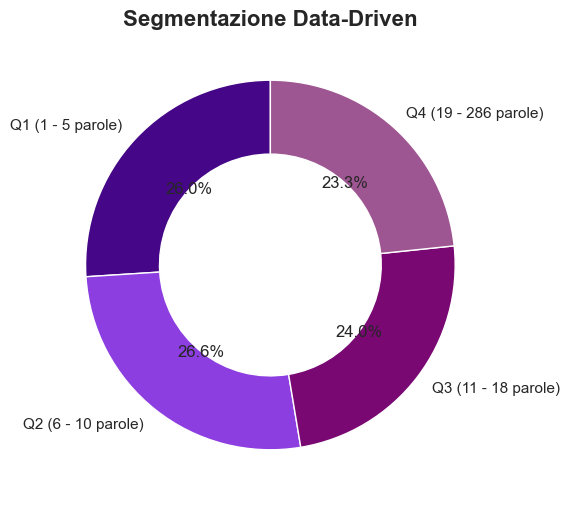

,Conteggio,Percentuale (%)
Range Estratto dai Dati,,
Q1 (1 - 5 parole),25374,26.01
Q2 (6 - 10 parole),25962,26.62
Q3 (11 - 18 parole),23430,24.02
Q4 (19 - 286 parole),22774,23.35


In [13]:
# Calcolo delle metriche di base se non disponibili
if 'Num_Parole' not in df_eda.columns:
    df_eda['Num_Parole'] = df_eda['Testo Tradotto'].apply(lambda x: len(str(x).split()))

# Suddivisione Data-Driven
# Eseguiamo qcut senza etichette per creare gli intervalli matematici
df_eda['Secchi_Quantili'] = pd.qcut(df_eda['Num_Parole'], q=4, duplicates='drop')

# Costruzione delle etichette dinamicamente
mappatura_etichette = {}
for i, intervallo in enumerate(df_eda['Secchi_Quantili'].cat.categories):
    # Cerchiamo il minimo e massimo reale all'interno di questo specifico gruppo
    min_reale = int(df_eda[df_eda['Secchi_Quantili'] == intervallo]['Num_Parole'].min())
    max_reale = int(df_eda[df_eda['Secchi_Quantili'] == intervallo]['Num_Parole'].max())
    
    if min_reale == max_reale:
        mappatura_etichette[intervallo] = f"Q{i+1} ({min_reale} parole)"
    else:
        mappatura_etichette[intervallo] = f"Q{i+1} ({min_reale} - {max_reale} parole)"

# Applicazione della mappatura dinamica e creazione di una colonna categorica ordinata
df_eda['Fascia_Quantili'] = df_eda['Secchi_Quantili'].map(mappatura_etichette)
df_eda['Fascia_Quantili'] = pd.Categorical(df_eda['Fascia_Quantili'], categories=list(mappatura_etichette.values()), ordered=True)

# Calcolo delle percentuali e visualizzazione grafica
distribuzione_quantili = df_eda['Fascia_Quantili'].value_counts().sort_index()
plt.figure(figsize=(10, 6))
colori_q = ["#450787", "#8D3EE0", '#790872', "#9e5692"] 
plt.pie(distribuzione_quantili, labels=distribuzione_quantili.index, autopct='%1.1f%%', startangle=90, colors=colori_q[:len(distribuzione_quantili)], wedgeprops={'width': 0.4, 'edgecolor': 'w'})
plt.title('Segmentazione Data-Driven', fontsize=16, fontweight='bold')
plt.show()

# Tabella riassuntiva
display(HTML("<h3><b>Dettaglio Numerico per Fascia</b> (Data-Driven):</h3>"))
df_riepilogo_quantili = pd.DataFrame({'Conteggio': distribuzione_quantili,'Percentuale (%)': (distribuzione_quantili / len(df_eda) * 100).round(2)})
df_riepilogo_quantili.index.name = 'Range Estratto dai Dati'
display(df_riepilogo_quantili)
df_eda.drop(columns=['Secchi_Quantili'], inplace=True)

Analizziamo la distribuzione del numero di parole per recensione, per capire se i dati siano bilanciati o asimmetrici nella produzione testuale degli utenti. 

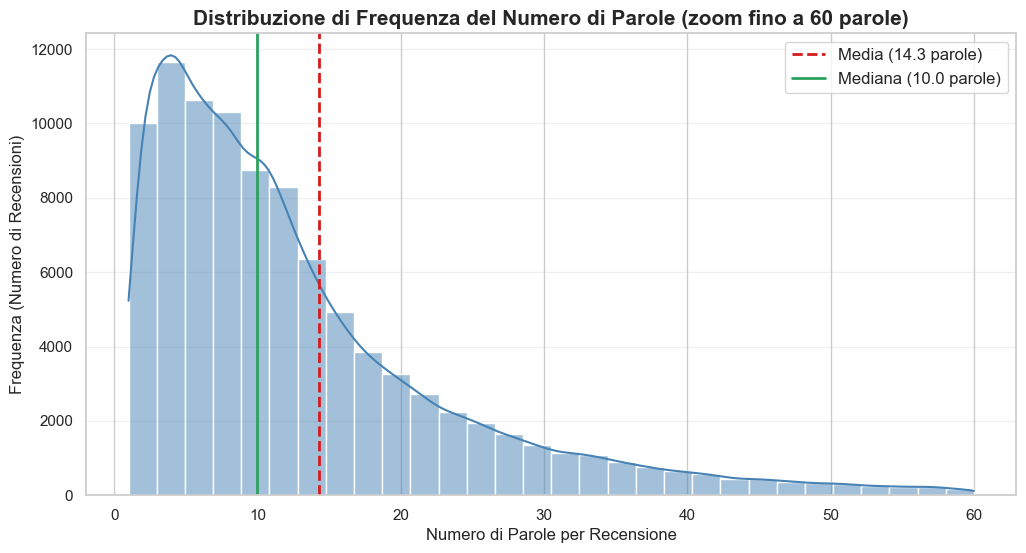

In [14]:
display(HTML("<h3><i>Quante parole scrivono gli utenti?</i></h3>"))
plt.figure(figsize=(12, 6))

# Filtriamo visivamente i dati fino a 60 parole per evitare l'effetto "schiacciamento" degli outlier
limite_visivo = 60
dati_filtrati = df_eda[df_eda['Num_Parole'] <= limite_visivo]

# Creiamo l'istogramma con la curva di densità sovrapposta
sns.histplot(data=dati_filtrati, x='Num_Parole', bins=30, kde=True, color='#4682B4', edgecolor='white')

# Media e mediana
media = df_eda['Num_Parole'].mean()
mediana = df_eda['Num_Parole'].median()
plt.axvline(media, color='#d7191c', linestyle='--', linewidth=2, label=f'Media ({media:.1f} parole)')
plt.axvline(mediana, color='#2ca25f', linestyle='-', linewidth=2, label=f'Mediana ({mediana:.1f} parole)')

plt.title('Distribuzione di Frequenza del Numero di Parole (zoom fino a 60 parole)', fontsize=15, fontweight='bold')
plt.xlabel('Numero di Parole per Recensione', fontsize=12)
plt.ylabel('Frequenza (Numero di Recensioni)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.show()

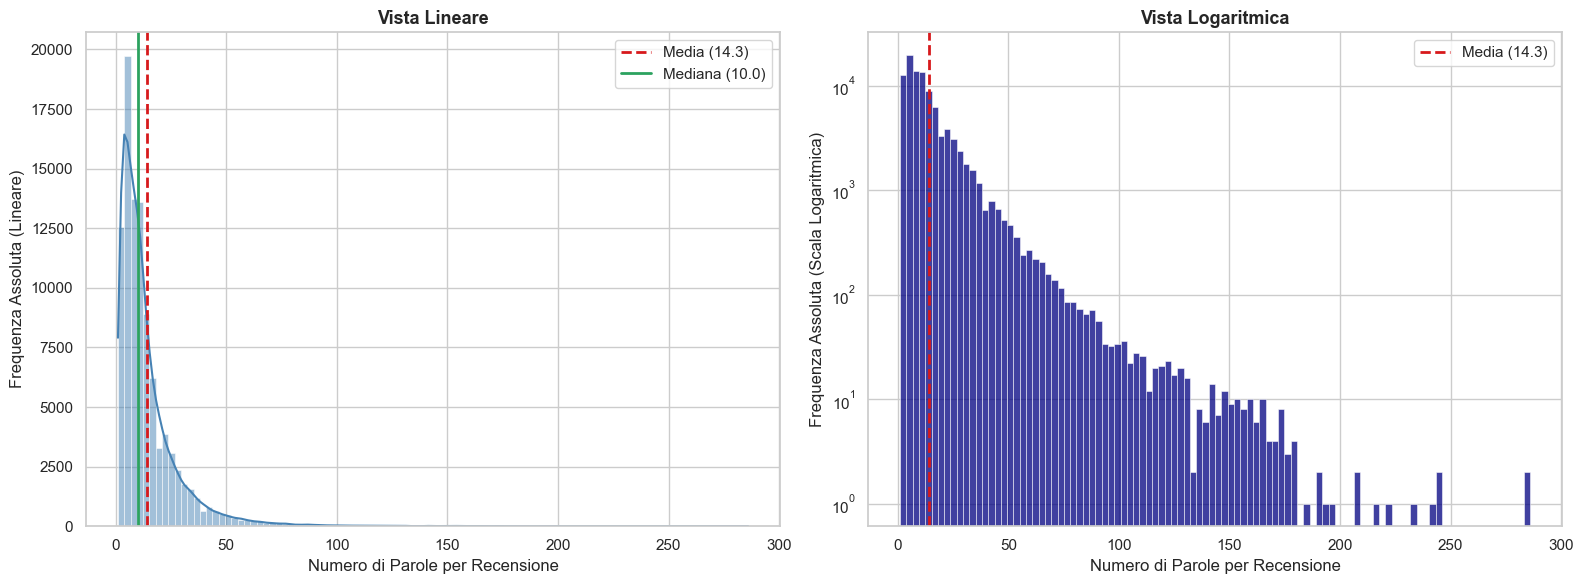

In [15]:
display(HTML("<h3>Distribuzione di Frequenza Completa</h3>"))

# Creiamo due grafici affiancati per confrontare la distribuzione
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
media = df_eda['Num_Parole'].mean()
mediana = df_eda['Num_Parole'].median()

# Grafico Completo Standard (Scala Lineare)
sns.histplot(data=df_eda, x='Num_Parole', bins=100, kde=True, color='#4682B4', edgecolor='white', ax=axes[0])
axes[0].axvline(media, color='#d7191c', linestyle='--', linewidth=2, label=f'Media ({media:.1f})')
axes[0].axvline(mediana, color='#2ca25f', linestyle='-', linewidth=2, label=f'Mediana ({mediana:.1f})')
axes[0].set_title('Vista Lineare', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Numero di Parole per Recensione')
axes[0].set_ylabel('Frequenza Assoluta (Lineare)')
axes[0].legend()

# Grafico Completo Logaritmico (scala Logaritmica su y)
sns.histplot(data=df_eda, x='Num_Parole', bins=100, color='#000080', edgecolor='white', ax=axes[1])
axes[1].set_yscale('log')
axes[1].axvline(media, color='#d7191c', linestyle='--', linewidth=2, label=f'Media ({media:.1f})')
axes[1].set_title('Vista Logaritmica', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Numero di Parole per Recensione')
axes[1].set_ylabel('Frequenza Assoluta (Scala Logaritmica)')
axes[1].legend()

plt.tight_layout()
plt.show()

Esploriamo la relazione tra la lunghezza delle recensioni e il voto generale assegnato dall’utente.

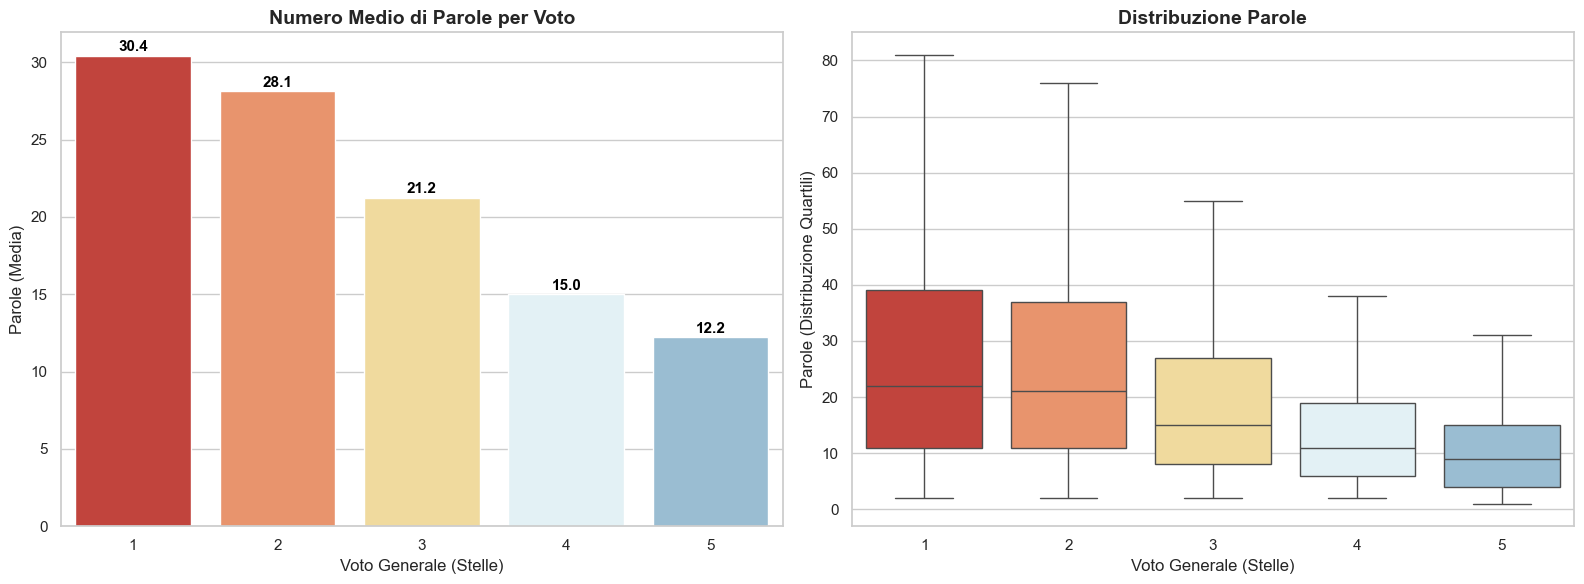

,Numero Recensioni,Media Parole,Mediana Parole,Max Assoluto Parole
Voto Generale Recensione,,,,
1,2950,30.42,22.0,245
2,2157,28.13,21.0,284
3,5847,21.24,15.0,208
4,21155,14.99,11.0,242
5,65431,12.22,9.0,286


In [ ]:
display(HTML("<h3>Analisi Comportamentale: Lunghezza vs Soddisfazione</h3>"))

# Calcoliamo le metriche raggruppate per ogni Voto Generale
lunghezza_media_per_voto = df_eda.groupby('Voto Generale Recensione')['Num_Parole'].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
palette_voti = ['#d73027', '#fc8d59', '#fee090', '#e0f3f8', '#91bfdb']

# Barplot: media delle parole
sns.barplot(data=lunghezza_media_per_voto, x='Voto Generale Recensione', y='Num_Parole', hue='Voto Generale Recensione', palette=palette_voti, ax=axes[0], legend = False)
axes[0].set_title('Numero Medio di Parole per Voto', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Voto Generale (Stelle)', fontsize=12)
axes[0].set_ylabel('Parole (Media)', fontsize=12)

for index, row in lunghezza_media_per_voto.iterrows():
    axes[0].text(index, row['Num_Parole'] + 0.3, f"{row['Num_Parole']:.1f}", color='black', ha="center", fontsize=11, fontweight='bold')

# Boxplot: distribuzione della massa
# Usiamo showfliers=False per nascondere i puntini neri degli outlier estremi, permettendoci di vedere chiaramente i quartili e la mediana
sns.boxplot(data=df_eda, x='Voto Generale Recensione', y='Num_Parole', hue='Voto Generale Recensione', palette=palette_voti, ax=axes[1], showfliers=False, legend=False)
axes[1].set_title('Distribuzione Parole', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Voto Generale (Stelle)', fontsize=12)
axes[1].set_ylabel('Parole (Distribuzione Quartili)', fontsize=12)

plt.tight_layout()
plt.show()

# Tabella riepilogativa
display(HTML("<h4>Dettaglio Statistico per Voto</h4>"))

# Calcoliamo count, media, mediana e massimo per ogni voto
dettaglio_voto = df_eda.groupby('Voto Generale Recensione')['Num_Parole'].agg(['count', 'mean', 'median', 'max']).round(2)
dettaglio_voto.columns = ['Numero Recensioni', 'Media Parole', 'Mediana Parole', 'Max Assoluto Parole']

display(dettaglio_voto)

### **4.2.3. Term Frequency ed emoji**

Analizzare i **termini più ricorrenti** nel contesto d'analisi è fondamentale per comprendere i temi dominanti e identificare eventuali stopwords di dominio poco discriminanti. Ma, oltre ai caratteri testuali in senso stretto, la comunicazione si arricchisce di altri elementi non meno informativi, tra cui le **emoji**, che sono in grado di intensificare o, in alcuni casi, ribaltare il significato di un messaggio.

-> **Term frequency**

Si carica la lista delle stopwords della lingua italiana tramite la libreria `nltk`, parole "vuote" che non portano significato semantico (tipo articoli, congiunzioni, preposizioni). Attraverso la classe `Counter`, viene calcolata la frequenza assoluta di ogni parola nel corpus. Da questa distribuzione vengono estratti: i 20 termini più frequenti.

In [ ]:
# TERM FREQUENCY
# Scarichiamo la lista delle stopwords italiane in modo silenzioso
nltk.download('stopwords', quiet=True)
stop_words_it = set(stopwords.words('italian'))

display(HTML("<h3>Analisi Lessicale (Termini più frequenti)</h3>"))

# Estrazione e pulizia al volo (solo per l'EDA)
def estrai_parole_chiave(testo):
    # Trasformiamo in minuscolo
    testo = str(testo).lower()
    # Estraiamo solo le parole (lettere dell'alfabeto, incluse accentate)
    parole = re.findall(r'\b[a-zàèéìíòóùú]+\b', testo)
    # Filtriamo le stopwords e le parole minuscole (es. "un", "ha")
    parole_pulite = [p for p in parole if p not in stop_words_it and len(p) > 2]
    return parole_pulite

# Applichiamo l'estrazione per creare una mega-lista di tutte le parole usate
df_eda['Parole_Pulite'] = df_eda['Testo Tradotto'].progress_apply(estrai_parole_chiave)
tutte_le_parole = [parola for sublist in df_eda['Parole_Pulite'] for parola in sublist]

# Conteggio e tabella dei 20 termini più frequenti (includente la frequenza assoluta e l'incidenza percentuale)
frequenze_parole = Counter(tutte_le_parole)
top_20_parole = frequenze_parole.most_common(20)

df_top_parole = pd.DataFrame(top_20_parole, columns=['Parola', 'Frequenza Assoluta'])
df_top_parole['Percentuale sul Totale Parole (%)'] = ((df_top_parole['Frequenza Assoluta'] / len(tutte_le_parole)) * 100).round(2)

display(HTML("<h3><b>Top 20 Parole</b> (escluse stopwords generiche):</h3>"))
# Trasponiamo per comodità visiva o mostriamo affiancato ai grafici
display(df_top_parole.head(10).T)

Rilevamento della lingua: 100%|██████████| 97540/97540 [00:01<00:00, 79614.02it/s] 


,0,1,2,3,4,5,6,7,8,9
Parola,ottimo,prodotto,molto,qualità,prezzo,buon,funzionale,facile,bello,rapporto
Frequenza Assoluta,33747,24686,22318,15405,15399,8723,8177,7959,7770,7455
Percentuale sul Totale Parole (%),3.9,2.85,2.58,1.78,1.78,1.01,0.94,0.92,0.9,0.86


In [ ]:
# Visualizzazione: barplot e wordcloud
display(HTML("<h3>Rappresentazione Grafica del Lessico</h3>"))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Barplot Orizzontale
sns.barplot(data=df_top_parole, x='Frequenza Assoluta', y='Parola', hue='Parola', palette='viridis', ax=axes[0], legend=False)
axes[0].set_title('Top 20 Termini Più Utilizzati', fontsize=15, fontweight='bold')
axes[0].set_xlabel('Frequenza Assoluta', fontsize=12)
axes[0].set_ylabel('Parola', fontsize=12)
axes[0].grid(axis='x', alpha=0.3)

# WordCloud (impatto visivo) 
# Generiamo la nuvola passando direttamente le frequenze già calcolate
wordcloud = WordCloud(width=800, height=500, background_color='white', colormap='ocean',max_words=100,contour_width=1, contour_color='steelblue').generate_from_frequencies(frequenze_parole)

axes[1].imshow(wordcloud, interpolation='bilinear')
axes[1].set_title('WordCloud del Dataset (Top 100 parole)', fontsize=15, fontweight='bold')
axes[1].axis('off') 

plt.tight_layout()
plt.show()

# Rimuoviamo la colonna di appoggio per non appesantire il dataFrame
df_eda.drop(columns=['Parole_Pulite'], inplace=True, errors='ignore')


### [Output rimosso per tutela della privacy e riservatezza commerciale]

-> **Extra: punteggiatura e formattazione**

Come primo step, ci concentriamo su tutto ciò che non è strettamente testuale ma che aggiunge forza al messaggio. Misuriamo la frequenza dei punti esclamativi e interrogativi perché rappresentano degli 'indicatori' dell'emozione: un eccesso di punteggiatura spesso segnala un coinvolgimento molto forte, sia esso di estrema soddisfazione o di profondo disappunto. Monitoriamo anche l'uso del testo interamente in maiuscolo, che nel linguaggio digitale viene utilizzato per dare massima rilevanza a un concetto. Invece di considerare questi elementi come semplice rumore da eliminare, li classifichiamo in livelli di intensità, creando una scala che ci aiuterà a pesare correttamente il sentiment di ogni recensione nelle analisi successive.

In [ ]:
# ENFASI TESTUALE
display(HTML("<h3>L'Enfasi Testuale (Punteggiatura e Maiuscole)</h3>"))

# Estrazione Metriche
df_eda['Punti_Esclamativi'] = df_eda['Testo Tradotto'].apply(lambda x: str(x).count('!'))
df_eda['Punti_Interrogativi'] = df_eda['Testo Tradotto'].apply(lambda x: str(x).count('?'))
df_eda['Tutto_Maiuscolo'] = df_eda['Testo Tradotto'].apply(lambda x: str(x).isupper())

# Creazione della variabile categorica per l'intensità
df_eda['Intensita_Esclamativa'] = pd.cut(df_eda['Punti_Esclamativi'], bins=[-1, 0, 2, 5, float('inf')], labels=['Nessuna', 'Moderata (1-2)', 'Alta (3-5)', 'Estrema (>5)'])

# Tabelle riassuntive
tot_eda = len(df_eda)
df_enfasi = pd.DataFrame({
    'Indicatore Testuale': ['>= 2 Punti Esclamativi', 'Tutto MAIUSCOLO', 'Presenza di Domande (?)'],
    'Occorrenze': [(df_eda['Punti_Esclamativi'] >= 2).sum(), df_eda['Tutto_Maiuscolo'].sum(), (df_eda['Punti_Interrogativi'] > 0).sum()],
    'Percentuale (%)': [round(((df_eda['Punti_Esclamativi'] >= 2).sum() / tot_eda) * 100, 2), round((df_eda['Tutto_Maiuscolo'].sum() / tot_eda) * 100, 2), round(((df_eda['Punti_Interrogativi'] > 0).sum() / tot_eda) * 100, 2)]})

dist_intensita = df_eda['Intensita_Esclamativa'].value_counts().sort_index()
df_intensita = pd.DataFrame({'Livello Intensità': dist_intensita.index,'Numero Recensioni': dist_intensita.values, 'Percentuale (%)': (dist_intensita.values / tot_eda * 100).round(2)})

display(HTML("<h3>-> Panoramica Numerica</h3>"))
display(df_enfasi)
display(HTML("<h3>-> Distribuzione Intensità Esclamativa</h3>"))
display(df_intensita)

# Ispezione Visiva Ordinata
display(HTML("<h3>-> Esempi per Livello di Intensità Esclamativa</h3>"))
for livello in df_eda['Intensita_Esclamativa'].cat.categories:
    subset = df_eda[df_eda['Intensita_Esclamativa'] == livello]
    display(HTML(f"<b>Livello: {livello}</b>"))
    if len(subset) > 0:
        with pd.option_context('display.max_colwidth', None):
            display(subset[['Voto Generale Recensione', 'Punti_Esclamativi', 'Testo Tradotto']].sample(min(2, len(subset)), random_state=42))
    else:
        display(HTML("<p><i>Nessuna recensione.</i></p>"))

display(HTML("<h3>-> Recensioni tutte in MAIUSCOLO</h3>"))
subset_maiuscolo = df_eda[df_eda['Tutto_Maiuscolo'] == True]
if len(subset_maiuscolo) > 0:
    with pd.option_context('display.max_colwidth', None):
        display(subset_maiuscolo[['Voto Generale Recensione', 'Num_Parole', 'Testo Tradotto']].sample(min(3, len(subset_maiuscolo)), random_state=42))

,Indicatore Testuale,Occorrenze,Percentuale (%)
0,>= 2 Punti Esclamativi,4128,4.23
1,Tutto MAIUSCOLO,1100,1.13
2,Presenza di Domande (?),554,0.57


,Livello Intensità,Numero Recensioni,Percentuale (%)
0,Nessuna,88530,90.76
1,Moderata (1-2),7207,7.39
2,Alta (3-5),1453,1.49
3,Estrema (>5),350,0.36


,Voto Generale Recensione,Punti_Esclamativi,Testo Tradotto
57355,5,0,"Belle, d'effetto. Ben rifinite, mi è piaciuto il doppio strato e la trasparenza media, molto belle in rapporto al prezzo."
91555,5,0,OTTIMISSIMO INCREDIBILMENTE SEDIE FAVOLOSE


,Voto Generale Recensione,Punti_Esclamativi,Testo Tradotto
3778,5,1,"Top! Comodissimo, discreto e resistente"
4853,5,1,Mi piace tantissimo io la uso come scarpiera!


,Voto Generale Recensione,Punti_Esclamativi,Testo Tradotto
51112,4,4,Comodo!! Comodo!!
73017,5,4,"Molto soddisfatta, vado spesso a fare acquisti!!!!"


,Voto Generale Recensione,Punti_Esclamativi,Testo Tradotto
39229,5,7,Ottimo tessuto !!! Ho comprato questo articolo all’angolo delle occasioni e devo dire che è un ottimo prodotto con materiale eccellente!! Lo consiglio sicuramente!!
96075,5,7,Quello che ci voleva!!!! Ne ho comprate un sacco!\nPerfette da montare a testa in su e a testa in giù!\nLa scanalatura è perfetta per quadri e foto. La versione di legno decappato molto strategica x bagno e cucina!


,Voto Generale Recensione,Num_Parole,Testo Tradotto
30543,4,24,"FUNZIONALE E MOLTO CARINO ESTETICAMENTE SI MONTA FACILMENTE NON PRENDE TANTO POSTO IDEALE PER AMBIENTI PICCOLI , COMODO PER SISTEMARE CAVI E DECODER VARI"
59280,5,5,ELEGANTE TROVO IL PRODOTTO ELEGANTE
38525,5,11,TESSUTO VERAMENTE ECCEZIONALE!!! STOFFA MORBIDA AL TATTO E PIACEVOLE SULLA PELLE!!!


-> **Uso e distribuzione delle emoji**

Un passaggio doveroso è la "normalizzazione": le emoji possono avere variazioni tecniche (come il colore della pelle o piccoli modificatori grafici) che per un computer risulterebbero simboli diversi. 

In [ ]:
# NORMALIZZAZIONE ED ESTRAZIONE DELLE EMOJI
display(HTML("<h3>Uso e Distribuzione delle Emoji</h3>"))

# Funzione di Estrazione e Normalizzazione
modificatore_emoji = ['\U0001F3FB', '\U0001F3FC', '\U0001F3FD','\U0001F3FE', '\U0001F3FF', '\uFE0F']

def extract_and_normalize_emojis(text):
    emojis_raw = [em['emoji'] for em in emoji.emoji_list(str(text))]
    emojis_clean = []
    for em in emojis_raw:
        for mod in modificatore_emoji:
            em = em.replace(mod, '')
        emojis_clean.append(em)
    return emojis_clean

df_eda['Lista_Emoji'] = df_eda['Testo Tradotto'].apply(extract_and_normalize_emojis)
df_eda['Num_Emoji'] = df_eda['Lista_Emoji'].apply(len)

# Metriche Globali
tot_eda = len(df_eda)
rec_con_emoji = (df_eda['Num_Emoji'] > 0).sum()

display(HTML(f"<p>Le recensioni contenenti almeno un'emoji sono <b>{rec_con_emoji}</b> (pari al <b>{round((rec_con_emoji / tot_eda) * 100, 2)}%</b> del dataset).</p>"))

# Estrazione Top 10 e Normalizzazione
tutte_le_emoji = [em for sublist in df_eda['Lista_Emoji'] for em in sublist]
emoji_uniche = len(set(tutte_le_emoji))

if tutte_le_emoji:
    display(HTML("<h3>Top 10 Emoji più frequenti:</h3>"))
    display(HTML(f"<p>Totale occorrenze: <b>{len(tutte_le_emoji)}</b> | Emoji uniche distinte: <b>{emoji_uniche}</b></p>"))
    
    top_emoji = Counter(tutte_le_emoji).most_common(10)
    max_freq = top_emoji[0][1]
    
    html_bars = "<div style='max-width: 600px;'>"
    for em, freq in top_emoji:
        width_pct = (freq / max_freq) * 100
        html_bars += f"""
        <div style='display:flex; align-items:center; margin-bottom:8px;'>
            <div style='width:40px; font-size:24px; text-align:center;'>{em}</div>
            <div style='flex-grow:1; background:#f0f0f0; margin-left:10px; border-radius:3px;'>
                <div style='width:{width_pct}%; background:#2ca25f; color:white; text-align:right; padding:4px; border-radius:3px; font-size:12px; font-weight:bold;'>
                    {freq}
                </div>
            </div>
        </div>
        """
    html_bars += "</div>"
    display(HTML(html_bars))

    # Ispezione Visiva Emoji
    display(HTML("<h3>Ispezione Visiva</h3>"))
    subset_emoji = df_eda[df_eda['Num_Emoji'] > 0]
    with pd.option_context('display.max_colwidth', None):
        display(subset_emoji[['Voto Generale Recensione', 'Lista_Emoji', 'Testo Tradotto']].sample(min(3, len(subset_emoji)), random_state=42))
else:
    display(HTML("<p><i>Nessuna emoji trovata nel dataset.</i></p>"))

,Voto Generale Recensione,Lista_Emoji,Testo Tradotto
31003,5,"[🤩, 🤩]",Prezzo topp consiglio 🤩 Prezzo topp consiglio 🤩
45578,5,[😊],Ottimo prodotto Prodotto molto carino x il suo designer che ricorda un po' quello nordico molto apprezzato anche dai commensali!!! 😊 Le ciotolina sono versatili se ne può fare l:usa più oppertuno!! Ottimo prodotto lo ricomprerei
63057,5,[👌],Tutto 👌 Tutto ok


In [21]:
display(HTML("<h3>Controllo Temporaneo: Griglia di tutte le Emoji Distinte</h3>"))

# Appiattiamo e rimuoviamo i duplicati
tutte_le_emoji_flat = [em for sublist in df_eda['Lista_Emoji'] for em in sublist]
emoji_uniche_set = sorted(list(set(tutte_le_emoji_flat))) 

# Creiamo una griglia HTML pulita
html_tutte = "<div style='display: flex; flex-wrap: wrap; gap: 8px; font-size: 22px; max-width: 800px;'>"
for em in emoji_uniche_set:
    html_tutte += f"<div style='background: #f9f9f9; padding: 5px 8px; border: 1px solid #ccc; border-radius: 4px; box-shadow: 1px 1px 3px rgba(0,0,0,0.1);'>{em}</div>"
html_tutte += "</div>"

display(HTML(html_tutte))

## **Conclusioni e Salvataggio**

In [ ]:
display(HTML("<h3>Ricostruzione dataset completo</h3>"))

# Dimensioni e join
n_df_originale = len(df)
n_df_eda       = len(df_eda)
n_testo_vuoto  = n_df_originale - n_df_eda
cols_da_eda = ['ID Recensione', 'Testo Tradotto']
df_master_completo = df.merge(df_eda[cols_da_eda], on='ID Recensione', how='left')

# Verifica del join
n_dopo_join = len(df_master_completo)
assert n_dopo_join == n_df_originale, f"ERRORE JOIN: righe attese {n_df_originale}, righe ottenute {n_dopo_join}"

display(HTML(f"<p>Join completato senza perdita di righe: <b>{n_dopo_join:,}</b> righe (attese {n_df_originale:,}).</p>"))

# Controllo: quante righe hanno Testo Tradotto nullo dopo il join?
testo_nullo_dopo = df_master_completo['Testo Tradotto'].isna().sum()
display(HTML(f"<p>Righe con <code>Testo Tradotto</code> = NaN dopo il join: <b>{testo_nullo_dopo:,}</b> ({testo_nullo_dopo/n_dopo_join*100:.2f}%).</p>"))

## Step 2: Selezione delle colonne e impostazione ID Recensione come indice
# Scelta delle colonne
display(HTML("<hr style='border-top: 1px solid #d3d3d3;'>"))
display(HTML("<h3>Selezione colonne e scelta dell'indice del DataFrame</h3>"))
COLONNE_MASTER = ['ID Recensione', 'Numero Articolo Catalogo', 'Testo Tradotto', 'Voto Generale Recensione', 'Raccomandato',                                  
    'Voto: Estetica', 'Voto: Facilità di montaggio/installazione', 'Voto: Come valuti la qualità del prodotto?', 'Voto: Rapporto qualità/prezzo',
    'Voto: Soddisfa le mie aspettative', 'Voto: Aiuta a risparmiare energia e/o acqua', 'Voto: Aiuta a ridurre/differenziare i rifiuti',]

# Verifica che tutte le colonne selezionate esistano davvero nel dataframe
colonne_mancanti = [c for c in COLONNE_MASTER if c not in df_master_completo.columns]
if colonne_mancanti:
    display(HTML(f"<p>ATT. Colonne non trovate: <code>{colonne_mancanti}</code></p>"))
else:
    display(HTML("<p>Tutte le colonne selezionate esistono nel DataFrame.</p>"))

df_nlp = df_master_completo[COLONNE_MASTER].copy()

# Scelta di ID Recensione come indice e verifica della sua unicità
df_nlp = df_nlp.set_index('ID Recensione')

display(HTML(f"<p>Indice impostato. Shape finale: <b>{df_nlp.shape[0]:,} righe × {df_nlp.shape[1]} colonne</b>.</p>"))

## Step 3: Report valori mancanti per colonna
display(HTML("<hr style='border-top: 1px solid #d3d3d3;'>"))
display(HTML("<h3>Valori mancanti per colonna</h3>"))
missing = df_nlp.isna().sum()
missing_pct = (missing / len(df_nlp) * 100).round(2)
df_missing_report = pd.DataFrame({'Colonna': missing.index, 'Valori Mancanti': missing.values, 'Percentuale (%)': missing_pct.values,}).sort_values('Valori Mancanti', ascending=False)
display(df_missing_report)

## Step 4: Salvataggio 
display(HTML("<hr style='border-top: 1px solid #d3d3d3;'>"))

cartella_destinazione = os.path.join("Circular Second Hand", "Analisi", "Analisi - Recensioni", "Risultati Analisi - Recensioni")
if not os.path.exists(cartella_destinazione):
    os.makedirs(cartella_destinazione)

nome_file_nlp = "2_text_eda__recensioni.csv"
percorso_salvataggio = os.path.join(cartella_destinazione, nome_file_nlp)

# Salvataggio con indice (ID Recensione)
df_nlp.to_csv(percorso_salvataggio, index=True, encoding='utf-8-sig')

display(HTML("<h4><b>Salvataggio completato</b></h4>"))
display(HTML(f"<ul><li>Il dataset è stato salvato con successo in: <b>{percorso_salvataggio}</b></li>"
             f"<li>Dimensioni file: {df_nlp.shape[0]:,} righe e {df_nlp.shape[1]} colonne.</li></ul>"))

,Colonna,Valori Mancanti,Percentuale (%)
10,Voto: Aiuta a ridurre/differenziare i rifiuti,95795,98.21
9,Voto: Aiuta a risparmiare energia e/o acqua,93021,95.36
5,Voto: Facilità di montaggio/installazione,23364,23.95
3,Raccomandato,3915,4.01
8,Voto: Soddisfa le mie aspettative,3480,3.57
4,Voto: Estetica,2510,2.57
6,Voto: Come valuti la qualità del prodotto?,2480,2.54
7,Voto: Rapporto qualità/prezzo,2297,2.35
1,Testo Tradotto,5,0.01
2,Voto Generale Recensione,0,0.00
